# 01 - OTP EDA and model review

This notebook reviews the BTS 2024 on-time performance extract and the trained
LightGBM delay-risk model. It reads the processed Parquet/DuckDB artifacts; it does
not retrain the model, so it runs in seconds.

**Cutoff discipline.** The model scores a flight 90 minutes before scheduled
departure. Inbound actuals are only used when they were observable by that cutoff
(`inbound_known = 1`). Test months (Nov-Dec) are strictly after training and
validation months.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
print("Repository root:", ROOT)


Repository root: D:\project learning


In [2]:
import json
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

from flightops.config import load_config

cfg = load_config()
con = duckdb.connect(str(cfg.path("data.otp.duckdb")), read_only=True)
metrics = json.loads((cfg.path("paths.metrics") / "otp_metrics.json").read_text())
insights = json.loads((cfg.path("paths.metrics") / "otp_insights.json").read_text())
overview = con.execute("SELECT * FROM otp_overview").fetchdf().iloc[0]
overview.to_dict()


{'flights': 7079059.0,
 'delayed_flights': 1443141.0,
 'delay_rate': 0.2066,
 'avg_dep_delay_min': 12.68,
 'cancellation_rate': 0.0136,
 'otp_rate': 0.783}

## 1. Dataset and provenance

In [3]:
print(f"Flights: {int(overview['flights']):,}")
print(f"Delay rate (>15 min): {overview['delay_rate']:.1%}")
print(f"OTP rate: {overview['otp_rate']:.1%}")
print(f"Average departure delay: {overview['avg_dep_delay_min']:.1f} min")
print(f"Cancellation rate: {overview['cancellation_rate']:.1%}")
print("\nSource: BTS On-Time Performance, 2024, all 12 months.")
print("Aircraft type is a synthetic enrichment because BTS has no equipment field.")


Flights: 7,079,059
Delay rate (>15 min): 20.7%
OTP rate: 78.3%
Average departure delay: 12.7 min
Cancellation rate: 1.4%

Source: BTS On-Time Performance, 2024, all 12 months.
Aircraft type is a synthetic enrichment because BTS has no equipment field.


## 2. Where delay risk concentrates

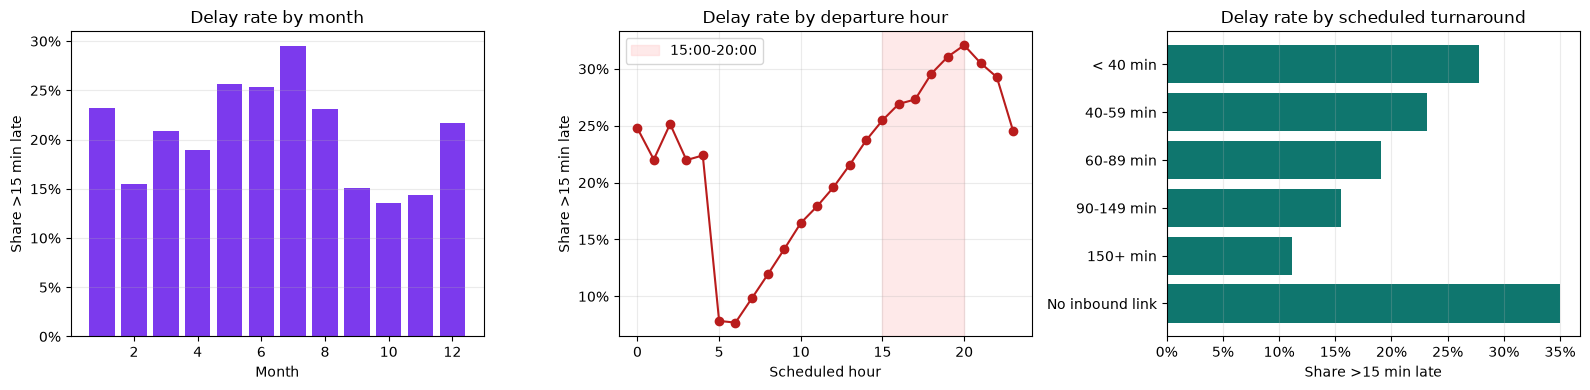

In [4]:
monthly = con.execute("SELECT * FROM otp_monthly ORDER BY month").fetchdf()
hourly = con.execute("SELECT * FROM otp_hour ORDER BY dep_hour").fetchdf()
turn = con.execute("SELECT * FROM turnaround_effect").fetchdf()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(monthly["month"], monthly["delay_rate"], color="#7c3aed")
axes[0].set(title="Delay rate by month", xlabel="Month", ylabel="Share >15 min late")
axes[0].yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[0].grid(axis="y", alpha=0.25)

axes[1].plot(hourly["dep_hour"], hourly["delay_rate"], marker="o", color="#b91c1c")
axes[1].set(title="Delay rate by departure hour", xlabel="Scheduled hour", ylabel="Share >15 min late")
axes[1].yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[1].grid(alpha=0.25)
axes[1].axvspan(15, 20, color="#fecaca", alpha=0.4, label="15:00-20:00")
axes[1].legend()

order = ["< 40 min", "40-59 min", "60-89 min", "90-149 min", "150+ min", "No inbound link"]
turn["scheduled_turn_bucket"] = pd.Categorical(turn["scheduled_turn_bucket"], order, ordered=True)
turn = turn.sort_values("scheduled_turn_bucket")
axes[2].barh(turn["scheduled_turn_bucket"].astype(str), turn["delay_rate"], color="#0f766e")
axes[2].set(title="Delay rate by scheduled turnaround", xlabel="Share >15 min late")
axes[2].xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[2].invert_yaxis()
axes[2].grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


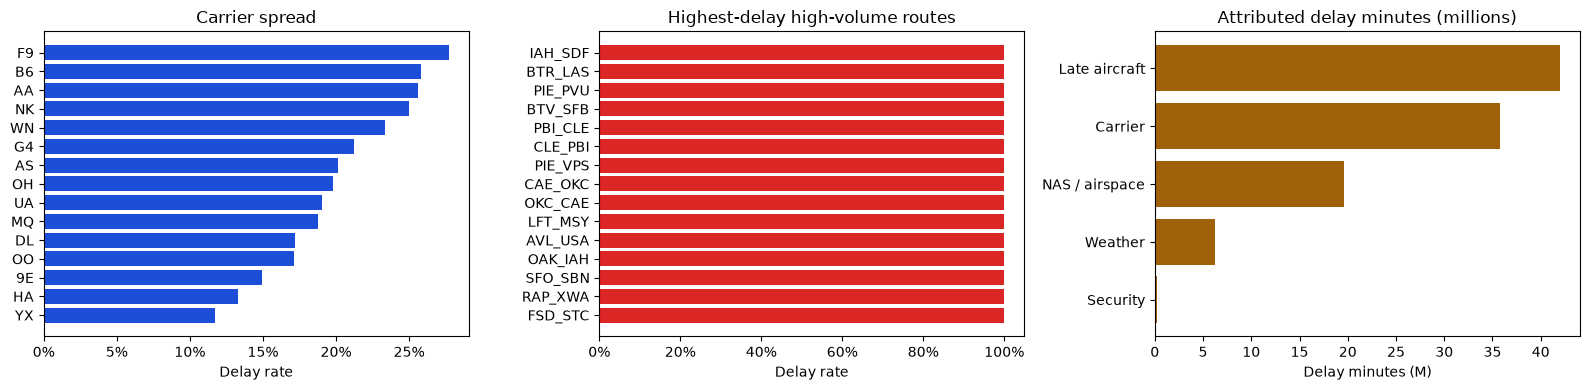

In [5]:
carriers = con.execute("SELECT * FROM otp_carrier ORDER BY delay_rate DESC").fetchdf()
routes = con.execute("SELECT * FROM otp_route ORDER BY delay_rate DESC LIMIT 15").fetchdf()
causes = con.execute("SELECT * FROM delay_cause_mix ORDER BY delay_minutes DESC").fetchdf()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].barh(carriers["carrier"], carriers["delay_rate"], color="#1d4ed8")
axes[0].set(title="Carrier spread", xlabel="Delay rate")
axes[0].xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[0].invert_yaxis()

axes[1].barh(routes["route"].astype(str), routes["delay_rate"], color="#dc2626")
axes[1].set(title="Highest-delay high-volume routes", xlabel="Delay rate")
axes[1].xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[1].invert_yaxis()

axes[2].barh(causes["cause"].astype(str), causes["delay_minutes"] / 1e6, color="#a16207")
axes[2].set(title="Attributed delay minutes (millions)", xlabel="Delay minutes (M)")
axes[2].invert_yaxis()
plt.tight_layout()
plt.show()


**Reading.** Delay risk climbs through the operating day and is highest on
short scheduled turnarounds. Carrier and route spreads are material, but these are
associations in observational data. Delay-cause fields are post-flight attributions
and are excluded from the model features.


## 3. Model performance on the held-out period

In [6]:
rows = []
for name in ["route_hour_baseline", "logistic_regression", "lightgbm"]:
    m = metrics["models"][name]
    rows.append({
        "model": name,
        "roc_auc": m["roc_auc"],
        "pr_auc": m["pr_auc"],
        "brier": m["brier"],
        "ece": m["ece"],
        "precision@0.5": m["precision"],
        "recall@0.5": m["recall"],
        "top_decile_lift": m["top_decile_lift"],
    })
comparison = pd.DataFrame(rows)
comparison.style.format({
    "roc_auc": "{:.3f}", "pr_auc": "{:.3f}", "brier": "{:.3f}", "ece": "{:.3f}",
    "precision@0.5": "{:.3f}", "recall@0.5": "{:.3f}", "top_decile_lift": "{:.2f}x",
})


,model,roc_auc,pr_auc,brier,ece,precision@0.5,recall@0.5,top_decile_lift
0,route_hour_baseline,0.625,0.249,0.145,0.038,0.000,0.000,1.61x
1,logistic_regression,0.747,0.520,0.117,0.043,0.798,0.279,3.76x
2,lightgbm,0.819,0.661,0.097,0.021,0.862,0.399,4.45x


In [7]:
print("Operating threshold:", metrics["operating_threshold"]["recommended"])
print("Cost-optimal threshold (validation):", metrics["operating_threshold"]["selected"])
print("Best LightGBM iteration:", metrics["best_iteration"])
print("Top-decile capture:", f"{metrics['business_case_top_decile']['recall']:.1%}")
print("Top-decile precision:", f"{metrics['business_case_top_decile']['precision']:.1%}")
print("Top-decile flag rate:", f"{metrics['business_case_top_decile']['flag_rate']:.1%}")


Operating threshold: 0.3048
Cost-optimal threshold (validation): 0.05
Best LightGBM iteration: 168
Top-decile capture: 49.2%
Top-decile precision: 72.9%
Top-decile flag rate: 12.2%


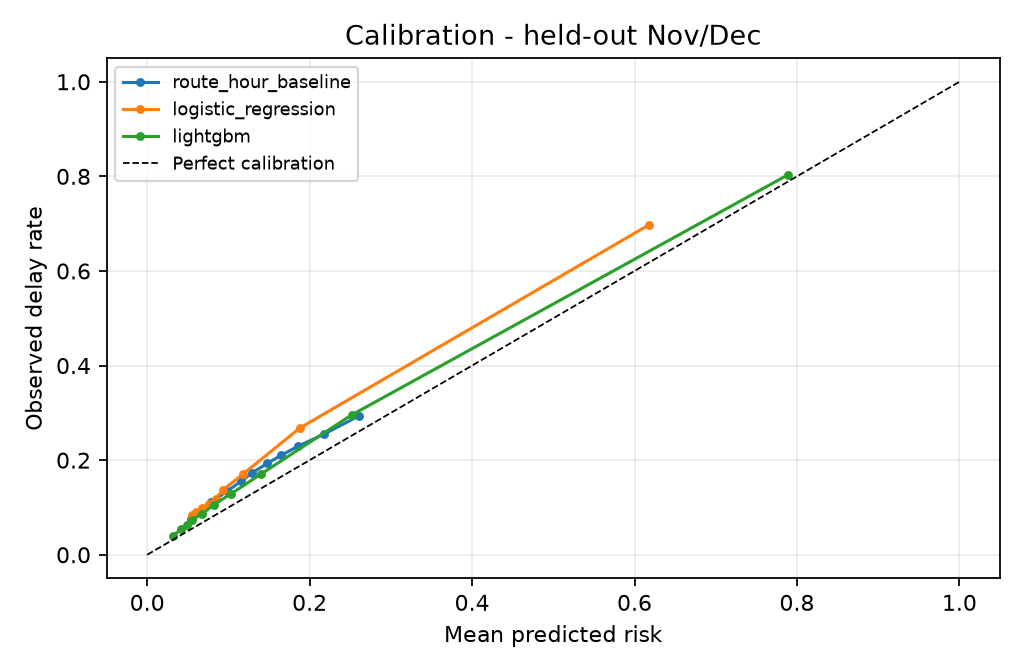

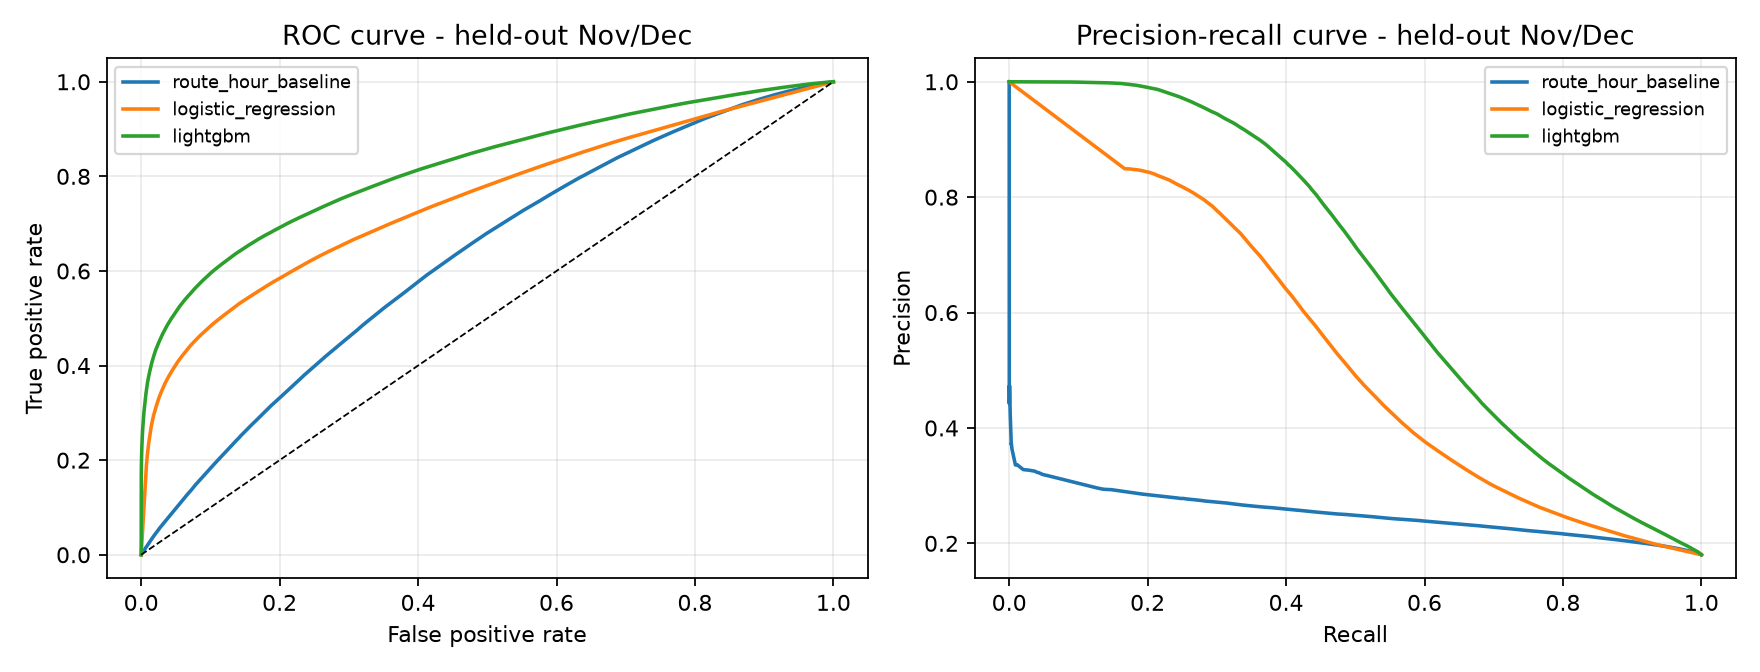

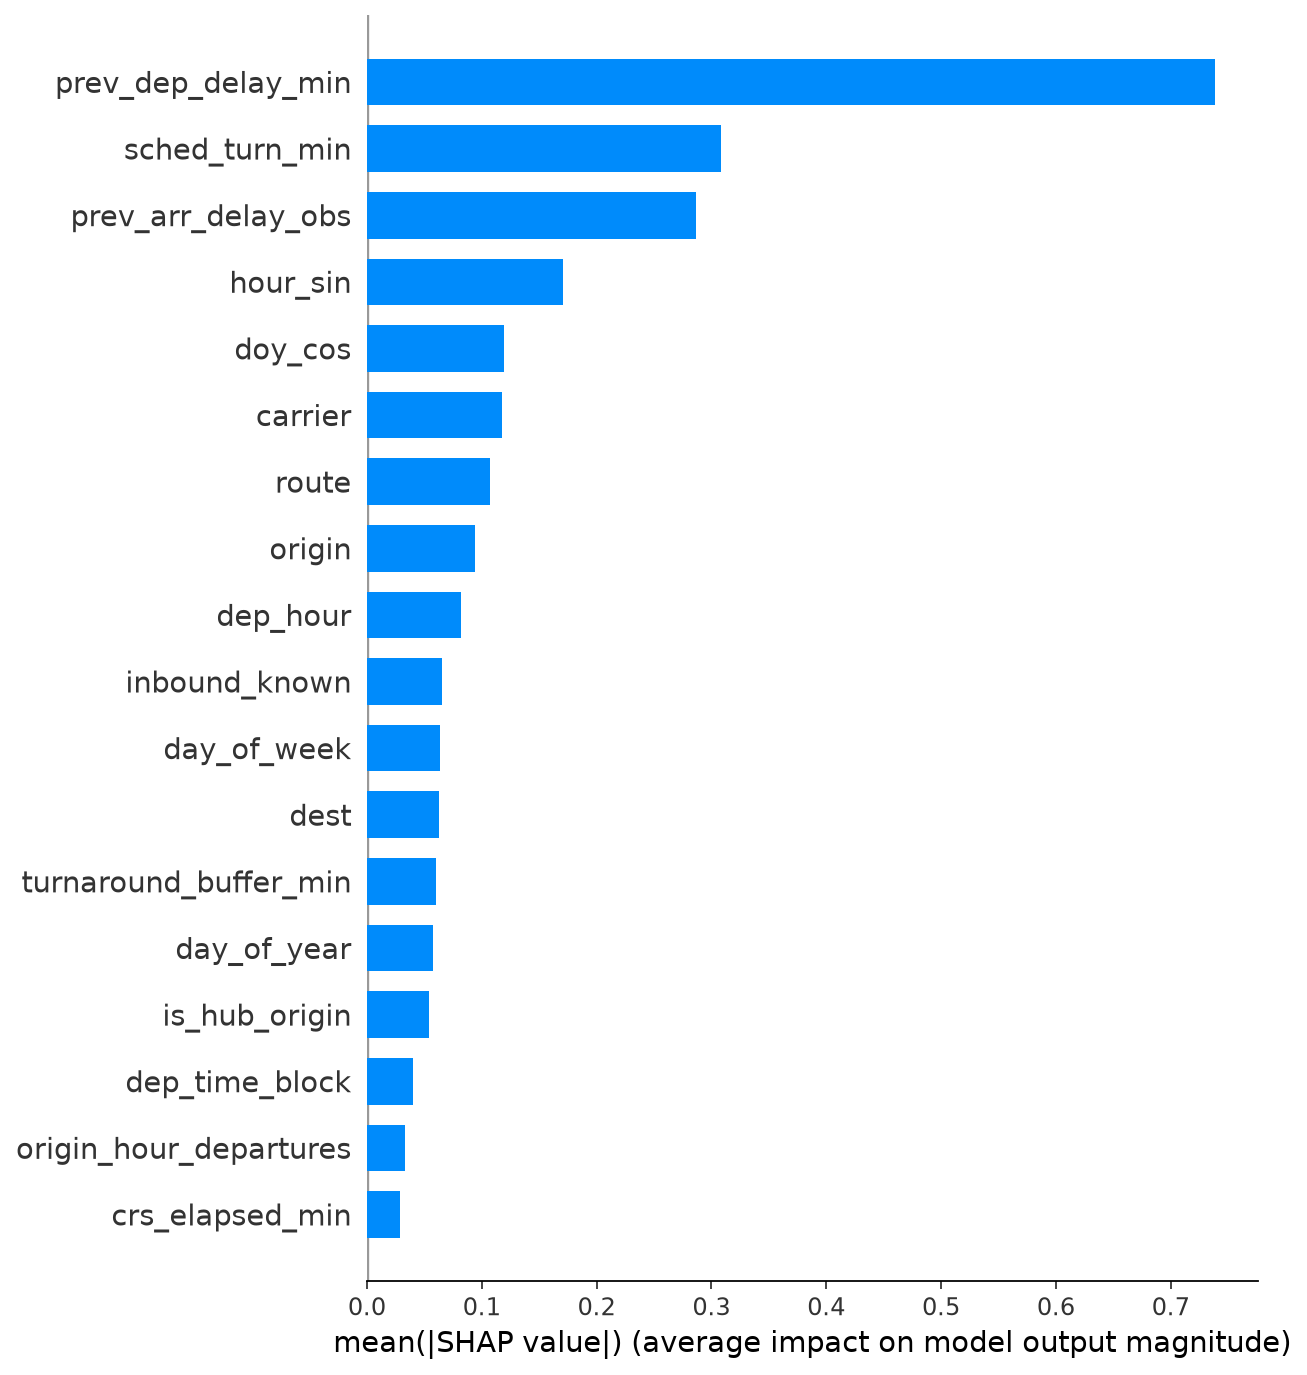

In [8]:
from IPython.display import Image, display

for name in ["otp_calibration.png", "otp_roc_pr.png", "otp_shap_bar.png"]:
    path = cfg.path("paths.figures") / name
    if path.exists():
        display(Image(filename=str(path), width=760))


## 4. Plain-language root cause

In [9]:
for item in insights["narrative"]:
    print("-", item)


- Across 7,079,059 scheduled flights in 2024, 20.7% departed more than 15 minutes late; the cancellation rate was 1.4%.
- The gradient-boosted model's SHAP attribution ranks turnaround & inbound aircraft as the largest driver group (56% of total absolute SHAP), followed by airport & network.
- Delay risk climbs through the day: the 15:00-20:00 block averages 28.6% versus 10.7% in the 06:00-09:00 window (2.7x).
- The late-aircraft association is visible in the turnaround data: flights with an inbound aircraft already 60+ minutes late depart late 16.6% of the time, versus 9.3% when the inbound is early. This is associational and is partly confounded by scheduled turnaround buffers.
- Scheduled turnarounds below 40 minutes show a 27.8% delay rate versus 15.5% for 90-149 minute turnarounds, consistent with little recovery buffer.
- Seasonality matters: month 7 is the worst month at 29.5% versus month 10 at 13.6%.
- Carrier spread is material: F9 delays 27.7% of departures versus YX at 11.7

## 5. Limitations

- Observational associations, not causal effects.
- Aircraft type is a deterministic synthetic enrichment; validate it against a
  real fleet registry before operational use.
- Weather is represented only by season/calendar proxies.
- The business case assumes a prevention rate; it is not a measured treatment effect.
